In [1]:
import numpy as np
from sklearn.datasets import make_classification

# Create dummy data
# The output of make_classification consists of feature data X and labels y
# The labels y will be encoded (numerical) data
X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# By default, make_classification produces float values
# We need to convert them to discrete form

# Take the absolute value of the values
X = np.absolute(X)

# Round values to two decimal places
# Multiply by 100 so that there are no decimal points
X = np.round(X, 2) * 100

# Convert to integer type
X = X.astype(int)

# Check the result
print(X)
print(y)

[[160  57]
 [ 96 137]
 [ 31   5]
 [  6   7]
 [152  81]
 [ 64  83]
 [122  65]
 [ 74 113]
 [ 18  33]
 [ 82  73]
 [ 62  85]
 [ 72  88]
 [188 149]
 [213 141]
 [ 78  88]
 [107  74]
 [263 210]
 [117  28]
 [ 76 101]
 [ 69 157]
 [ 10  22]
 [206 263]
 [136 200]
 [141  67]
 [173 119]
 [145  83]
 [101  73]
 [146 125]
 [106  66]
 [ 67 140]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [3]:
import pandas as pd

# Reshape label y into 2D
# This is done because we will concatenate it with the feature data X
y_new = y.reshape(len(y), 1)

# Concatenate features X and label y into an array
data = np.concatenate((X, y_new), axis=1)

# Define column names
nama_kolom = ['Feature 1', 'Feature 2', 'Label']

# Create DataFrame
df = pd.DataFrame(data, columns=nama_kolom)

# Inspect the DataFrame
df.head()

,Feature 1,Feature 2,Label
0,160,57,0
1,96,137,0
2,31,5,0
3,6,7,0
4,152,81,0


In [4]:
# Define label names
labels = {
    1 : 'Class A',
    0 : 'Class B'
}

# Copy the DataFrame to create a new DataFrame
# with more readable labels
df_label = df.copy()

# Replace labels using the Pandas mapping function
# on the df_label DataFrame
df_label['Label'] = df_label['Label'].map(labels)

# Inspect the df_label DataFrame
df_label.head()

,Feature 1,Feature 2,Label
0,160,57,Class B
1,96,137,Class B
2,31,5,Class B
3,6,7,Class B
4,152,81,Class B


In [9]:
print(df_label['Label'].value_counts())

Label
Class B    15
Class A    15
Name: count, dtype: int64


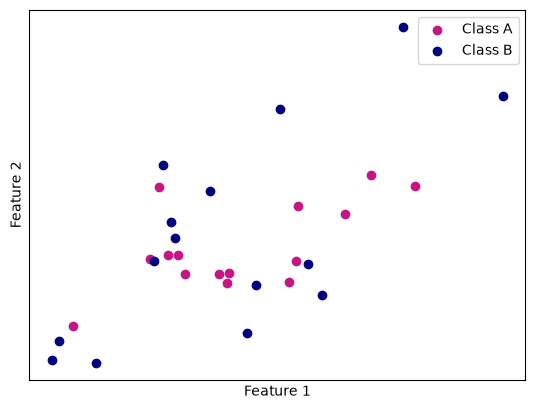

In [14]:
import matplotlib.pyplot as plt

colors = {
    'Class A': 'MediumVioletRed',
    'Class B': 'Navy'
}

# Group by column string directly (no list brackets)
gb = df_label.groupby('Label')
class_a = gb.get_group('Class A')
class_b = gb.get_group('Class B')

# Plot
plt.scatter(x=class_a['Feature 1'], y=class_a['Feature 2'], c=colors['Class A'], label='Class A')
plt.scatter(x=class_b['Feature 1'], y=class_b['Feature 2'], c=colors['Class B'], label='Class B')

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()

# Clean tick removal
plt.xticks([])
plt.yticks([])

plt.show()

In [16]:
from sklearn.naive_bayes import MultinomialNB # class for the MultinomialNB model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluate the model using accuracy

# Instantiate a MultinomialNB object
mnb = MultinomialNB()

# We can directly use the feature matrix X and labels y
# resulting from the dummy data generation process

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit the model
# The label y must be in 1D form or (n_samples,)
mnb.fit(X_train, y_train)

# Predict on training data
y_train_pred = mnb.predict(X_train)

# Evaluate training accuracy
acc_train = accuracy_score(y_train, y_train_pred)

# Predict test data
y_test_pred = mnb.predict(X_test)

# Evaluate the model using the accuracy metric
acc_test = accuracy_score(y_test, y_test_pred)

# Print evaluation results
print(f'Training accuracy: {acc_train}')
print(f'Test accuracy: {acc_test}')

Training accuracy: 0.6666666666666666
Test accuracy: 0.5555555555555556


In [17]:
from sklearn.naive_bayes import GaussianNB # class for the GaussianNB model

# Instantiate a Gaussian object
gnb = GaussianNB()

# We use the same training and testing split
# as used for the multinomial model

# Fit the model
# The label y must be in 1D form or (n_samples,)
gnb.fit(X_train, y_train)

# Predict on training data
y_train_pred_gnb = gnb.predict(X_train)

# Evaluate training accuracy
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Predict test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluate the model using the accuracy metric
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print evaluation results
print(f'Training accuracy (Gaussian): {acc_train_gnb}')
print(f'Test accuracy (Gaussian): {acc_test_gnb}')

Training accuracy (Gaussian): 0.7142857142857143
Test accuracy (Gaussian): 0.6666666666666666
